<a href="https://colab.research.google.com/github/nermeenfarg/DEPI-Sample-Proposals/blob/main/orbitra_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Orbitra Electronics: 2024-2025 Commercial Performance Review (AR-2026-007)
Notebook: load → audit → clean → analyse → chart → export.
**Before running:** put the two CSV files next to the notebook (or change `DATA_DIR`).

In [45]:
import os, difflib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = "/"
ORDERS_FILE = f"{DATA_DIR}/orbitra_orders_2024_2025.csv"
PRODUCTS_FILE = f"{DATA_DIR}/orbitra_products.csv"
os.makedirs("charts", exist_ok=True)

# ---- parameters you may need to tune after looking at the data ----
TEST_REGEX = r"test|qa|dummy|demo"                       # QA/test order markers (order_id / customer_id)
QTY_CAP = {"Consumer": 20, "Small Business": 200}        # max believable units per line
PRICE_RATIO_HI, PRICE_RATIO_LO = 3.0, 1/3                # price vs. product-quarter median
ON_TIME_DAYS = 3
WHITE_FRIDAY = {2024: ("2024-11-29", "2024-12-05"), 2025: ("2025-11-28", "2025-12-04")}

## Phase 1: First look (raw files are never modified)

In [46]:
def read_any(path):
    """Read as text. Handles real CSVs and Excel files that were saved with a .csv name."""
    try:
        return pd.read_csv(path, dtype=str)
    except (UnicodeDecodeError, pd.errors.ParserError):
        return pd.read_excel(path, dtype=str, engine="openpyxl")
raw = read_any(ORDERS_FILE)          # everything as text first: we convert types ourselves
raw = raw.dropna(how="all")
prod_raw = (pd.read_csv(PRODUCTS_FILE, dtype=str) if os.path.exists(PRODUCTS_FILE)
            else pd.read_excel(PRODUCTS_FILE.replace(".csv", ".xlsx"), dtype=str))
print("orders:", raw.shape, "| products:", prod_raw.shape)
display(raw.head()); display(raw.tail())
raw.info()
display(prod_raw.head())

orders: (16442, 18) | products: (136, 7)


,order_id,line_no,order_date,customer_id,customer_segment,city,region,channel,product_id,quantity,unit_price,discount,unit_cost,shipping_fee,payment_method,order_status,delivery_date,customer_rating
0,ORB-100231,1,2024-01-01 01:41:32,C101853,Consumer,Cairo,Greater Cairo,Mobile App,P-1131,1,404,0.15,224.01,60,mobile wallet,Returned,2024-01-02 00:00:00,3
1,ORB-100232,1,2024-01-01 02:55:44,C100188,Consumer,Cairo,Greater Cairo,Mobile App,P-1115,3,414,NaN,NaN,60,Credit Card,Delivered,2024-01-04 00:00:00,NaN
2,ORB-100233,1,2024-01-01 06:02:43,C103815,Consumer,Giza,Greater Cairo,Store,P-1119,2,709,NaN,NaN,0,Installments,Delivered,NaN,4
3,ORB-100234,1,2024-01-01 11:45:56,C104898,Consumer,Assiut,Upper Egypt,Store,P-1021,1,1569,0.05,1250.63,0,Cash,Delivered,NaN,NaN
4,ORB-100235,1,2024-01-01 12:26:37,C100276,Consumer,Giza,Greater Cairo,Store,P-1118,2,514,NaN,282.3,0,Installments,Delivered,NaN,NaN


,order_id,line_no,order_date,customer_id,customer_segment,city,region,channel,product_id,quantity,unit_price,discount,unit_cost,shipping_fee,payment_method,order_status,delivery_date,customer_rating
16437,ORB-111436,1,31/12/2025 16:40,C102529,Consumer,Cairo,Greater Cairo,Store,P-1100,1,"EGP 1,329.00",NaN,924.44,0,Credit Card,Delivered,NaN,NaN
16438,ORB-111437,1,31/12/2025 17:48,C101635,Consumer,Assiut,Upper Egypt,App,P-1081,1,"EGP 1,234.00",0.15,826.09,78,Cash on Delivery,Pending,NaN,NaN
16439,ORB-111438,1,31/12/2025 17:57,C104081,Consumer,Hurghada,Red Sea,App,P-1132,1,EGP 934.00,NaN,495.42,78,Cash on Delivery,Pending,NaN,NaN
16440,ORB-111439,1,31/12/2025 20:18,C104081,Consumer,Hurghada,Red Sea,Website,P-1090,3,"EGP 3,774.00",0,2673.57,0,Cash on Delivery,Cancelled,NaN,NaN
16441,ORB-111440,1,31/12/2025 21:38,C101371,Consumer,Giza,Greater Cairo,Store,P-1084,1,"EGP 1,499.00",0,1022.13,0,Credit Card,Delivered,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16442 entries, 0 to 16441
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   order_id          16442 non-null  object
 1   line_no           16442 non-null  object
 2   order_date        16442 non-null  object
 3   customer_id       16442 non-null  object
 4   customer_segment  16442 non-null  object
 5   city              16442 non-null  object
 6   region            15704 non-null  object
 7   channel           16442 non-null  object
 8   product_id        16442 non-null  object
 9   quantity          16442 non-null  object
 10  unit_price        16442 non-null  object
 11  discount          9930 non-null   object
 12  unit_cost         16021 non-null  object
 13  shipping_fee      16127 non-null  object
 14  payment_method    16442 non-null  object
 15  order_status      16442 non-null  object
 16  delivery_date     10545 non-null  object
 17  customer_rat

,product_id,product_name,category,sub_category,brand,launch_date,warranty_months
0,P-1001,"""Lumora 43"""" Full HD TV""",TV & Audio,Televisions,Lumora,2023-11-10 00:00:00,24
1,P-1002,"""Orvelle 43"""" Full HD TV""",TV & Audio,Televisions,Orvelle,2022-05-25 00:00:00,24
2,P-1003,"""Halvio 43"""" Full HD TV""",TV & Audio,Televisions,Halvio,2021-11-16 00:00:00,24
3,P-1004,"""Lumora 50"""" 4K Smart TV""",TV & Audio,Televisions,Lumora,2022-05-14 00:00:00,24
4,P-1005,"""Tamaro 50"""" 4K Smart TV""",TV & Audio,Televisions,Tamaro,2022-05-21 00:00:00,24


In [47]:
# distinct values for every low-cardinality text column
for c in ["customer_segment", "city", "region", "channel", "payment_method", "order_status", "discount", "customer_rating"]:
    print(f"\n--- {c} ---"); print(raw[c].value_counts(dropna=False).head(25))
for c in ["category", "sub_category", "brand", "warranty_months"]:
    print(f"\n--- products.{c} ---"); print(prod_raw[c].value_counts(dropna=False))


--- customer_segment ---
customer_segment
Consumer          15477
Small Business      965
Name: count, dtype: int64

--- city ---
city
Cairo                  4848
Hurghada               2237
Alexandria             1898
Giza                   1840
Mansoura               1329
Assiut                  733
Tanta                   658
6th of October          646
Port Said               536
Zagazig                 519
Aswan                   388
Hurgada                 138
CAIRO                    84
El Qahira                79
Cairo                    70
cairo                    67
giza                     65
El Giza                  64
Alexandria               46
alexandria               44
Alex                     43
Assuit                   26
2026-10-06 00:00:00      20
Asyut                    19
Port-Said                15
Name: count, dtype: int64

--- region ---
region
Greater Cairo         7440
Alexandria & Canal    2462
Delta                 2404
Red Sea               2270
Upper E

In [48]:
def missing_table(d):
    t = pd.DataFrame({"missing": d.isna().sum(), "pct": (d.isna().mean() * 100).round(2)})
    return t.sort_values("pct", ascending=False)
display(missing_table(raw)); display(missing_table(prod_raw))

,missing,pct
customer_rating,11301,68.73
discount,6512,39.61
delivery_date,5897,35.87
region,738,4.49
unit_cost,421,2.56
shipping_fee,315,1.92
line_no,0,0.00
order_id,0,0.00
customer_segment,0,0.00
order_date,0,0.00


,missing,pct
warranty_months,4,2.94
product_name,0,0.00
product_id,0,0.00
category,0,0.00
sub_category,0,0.00
brand,0,0.00
launch_date,0,0.00


## Phase 2 + 3: Data-quality audit and cleaning (each fix is logged with rows affected)

In [49]:
dq = []
def log(column, issue, rows, example="", decision="", impact=""):
    dq.append({"ID": f"DQ-{len(dq)+1:02d}", "column": column, "issue": issue, "rows": int(rows),
               "example": str(example)[:90], "decision": decision, "impact": impact})

def standardize(s, min_share=0.002, cutoff=0.8):
    """Merge spelling/case/punctuation variants; rare variants are fuzzy-matched to frequent labels."""
    s = s.astype("string").str.strip()
    k = s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    tmp = pd.DataFrame({"raw": s, "k": k}).dropna()
    def best(x):
        vc = x.value_counts()
        mixed = [v for v in vc.index if v != v.lower() and v != v.upper()]
        return mixed[0] if mixed else vc.index[0]
    canon = tmp.groupby("k")["raw"].agg(best)
    kc = tmp["k"].value_counts()
    frequent = kc[kc >= max(2, min_share * len(tmp))].index.tolist()
    kmap = {}
    for kk in kc.index:
        m = [kk] if kk in frequent else difflib.get_close_matches(kk, frequent, n=1, cutoff=cutoff)
        kmap[kk] = m[0] if m else kk
    return k.map(kmap).map(canon)

def map_labels(s, mapping):
    k = s.astype("string").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return k.map(mapping)

def to_num(s):
    return pd.to_numeric(s.astype("string").str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")

def parse_dates(s):
    s = s.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%d/%m/%Y %H:%M:%S", "%d/%m/%Y", "%d/%m/%Y %H:%M"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

In [50]:
# ---------- 3.1 products catalog ----------
prod = prod_raw.copy()
for c in prod.columns: prod[c] = prod[c].str.strip()
prod["product_id"] = prod["product_id"].str.upper()
n0 = len(prod)
exact = prod.duplicated().sum()
prod = prod.drop_duplicates()
dupe_ids = prod["product_id"].duplicated(keep=False)
if dupe_ids.any():
    print("Conflicting duplicate product codes:"); display(prod[dupe_ids].sort_values("product_id"))
log("products.product_id", "Duplicated product codes (exact copies removed; conflicting ones keep first)",
    exact + prod["product_id"].duplicated().sum(), prod.loc[dupe_ids, "product_id"].head(1).tolist(),
    "Drop exact duplicates, keep first row for the rest", "Would double-count revenue after merge")
prod = prod.drop_duplicates("product_id", keep="first")
for c in ["category", "sub_category", "brand"]:
    before = prod[c].copy(); prod[c] = standardize(prod[c], min_share=0, cutoff=0.85)
    log(f"products.{c}", "Inconsistent labels in catalog", (before != prod[c]).sum(), "", "Standardised", "Category totals split")
nq = prod["product_name"].str.contains('"', na=False).sum()
prod["product_name"] = prod["product_name"].str.strip('"').str.replace('""', '"', regex=False)
log("products.product_name", "CSV quote artefacts around names (e.g. '\"Lumora 43\"\" TV\"')", nq, "", "Strip wrapping quotes, un-double inner quotes", "Cosmetic (labels in charts)")
prod["launch_date"] = parse_dates(prod["launch_date"])
prod["warranty_months"] = pd.to_numeric(prod["warranty_months"], errors="coerce")
print(prod.category.value_counts())

Conflicting duplicate product codes:


,product_id,product_name,category,sub_category,brand,launch_date,warranty_months
48,P-1049,Vantrix Gaming Laptop (2025 model),Computing,Laptops,Vantrix,2022-10-23 00:00:00,12
49,P-1049,Vantrix Gaming Laptop,Computing,Laptops,Vantrix,2022-10-23 00:00:00,12
55,P-1055,"""Halvio 24"""" IPS Monitor""",Computing,Monitors,Halvio,2022-09-15 00:00:00,24
56,P-1055,"""Halvio 24"""" IPS Monitor (2025 model)""",Computing,Monitors,Halvio,2022-09-15 00:00:00,24
112,P-1111,Kestro USB-C Cable 1m (2025 model),Accessories,Chargers & Cables,Kestro,2023-10-07 00:00:00,6
113,P-1111,Kestro USB-C Cable 1m,Accessories,Chargers & Cables,Kestro,2023-10-07 00:00:00,6


category
Small Appliances     27
Accessories          27
TV & Audio           25
Computing            20
Large Appliances     18
Mobiles & Tablets    16
Name: count, dtype: Int64


In [51]:
# ---------- 3.2 orders: types ----------
df = raw.copy()
for c in df.columns: df[c] = df[c].str.strip()
df = df.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan, "NULL": np.nan})
df["product_id"] = df["product_id"].str.upper()

# Excel/CSV tools can silently read ERP "DD/MM/YYYY" dates as MM/DD/YYYY when the day is <= 12, turning them into ISO
# dates with day and month swapped. ERP rows are recognisable by the text price ("EGP ..."), so we undo the swap there.
erp_rows = df["unit_price"].str.contains("EGP", na=False)
def unswap(s, mask):
    iso = mask & s.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)
    t = pd.to_datetime(s[iso], errors="coerce")
    s = s.copy(); s[iso] = t.dt.strftime("%m/%d/%Y %H:%M:%S")      # t.month holds the original day, t.day the original month
    return s, int(iso.sum())
df["order_date"], n_od = unswap(df["order_date"], erp_rows)
df["delivery_date"], n_dd = unswap(df["delivery_date"], erp_rows)
log("order_date / delivery_date", "ERP dates with day/month swapped by the export tool (ISO-looking dates on ERP rows)", n_od + n_dd,
    "2025-01-07 → 1 Jul 2025", "Swap day and month back for ERP rows (verified: order_id order matches date order)", "Orders land in the wrong month; negative / huge delivery days")
has_time = df["order_date"].str.contains(":", na=False)
df["order_date_has_time"] = has_time
bad_dates = parse_dates(df["order_date"]).isna() & df["order_date"].notna()
df["order_date"] = parse_dates(df["order_date"]); df["delivery_date"] = parse_dates(df["delivery_date"])
log("order_date / delivery_date", "Two date formats (ISO vs DD/MM/YYYY after ERP go-live)",
    (raw["order_date"].str.contains("/", na=False)).sum(), raw.loc[raw["order_date"].str.contains("/", na=False), "order_date"].head(1).tolist(),
    "Parse each format separately and combine", "Wrong month if day/month swapped")
log("order_date", "Unparseable dates", bad_dates.sum(), "", "Rows dropped", "")

price_text = raw["unit_price"].str.contains(r"[A-Za-z,]", na=False).sum()
log("unit_price", "Price stored as text ('EGP 12,499.00')", price_text,
    raw.loc[raw["unit_price"].str.contains("EGP", na=False), "unit_price"].head(1).tolist(), "Strip text, convert to float", "Revenue would be NaN for ERP rows")
for c in ["unit_price", "unit_cost", "shipping_fee", "quantity", "customer_rating"]:
    df[c] = to_num(df[c])

d = df["discount"].astype("string")
pct_text = d.str.contains("%", na=False).sum()
df["discount"] = to_num(d)
gt1 = (df["discount"] > 1).sum()
df.loc[df["discount"] > 1, "discount"] /= 100          # 15 → 0.15
log("discount", "Discount written as % / whole number instead of a share", pct_text + gt1, "15% / 15", "Convert to 0-1 share", "Margins overstated")
log("discount", "Blank discount", df["discount"].isna().sum(), "", "Blank = no discount → 0", "")
df["discount"] = df["discount"].fillna(0)

In [52]:
# ---------- 3.3 labels ----------
CH = {"store": "Store", "showroom": "Store", "website": "Website", "web": "Website", "online": "Website", "site": "Website", "instore": "Store",
      "mobileapp": "Mobile App", "app": "Mobile App", "mobile": "Mobile App"}
PAY = {"cash": "Cash", "creditcard": "Credit Card", "credit": "Credit Card", "debitcard": "Debit Card", "debit": "Debit Card",
       "installments": "Installments", "installment": "Installments", "instalments": "Installments",
       "mobilewallet": "Mobile Wallet", "wallet": "Mobile Wallet", "ewallet": "Mobile Wallet", "visamastercard": "Credit Card", "cc": "Credit Card", "cashondelivery": "Cash on Delivery", "cod": "Cash on Delivery"}
ST = {"delivered": "Delivered", "returned": "Returned", "cancelled": "Cancelled", "canceled": "Cancelled", "pending": "Pending", "intransit": "Pending"}
SEG = {"consumer": "Consumer", "consumers": "Consumer", "b2c": "Consumer", "smallbusiness": "Small Business", "sme": "Small Business", "business": "Small Business", "b2b": "Small Business"}

for col, mp in [("channel", CH), ("payment_method", PAY), ("order_status", ST), ("customer_segment", SEG)]:
    before = df[col].copy(); new = map_labels(before, mp)
    unmapped = before[new.isna() & before.notna()].unique()
    if len(unmapped): print(f"⚠️ {col}: unmapped values -> extend the dict:", unmapped)
    changed = ((before != new) & before.notna()).sum()
    log(col, "Same value written in several ways", changed, before[(before != new) & before.notna()].head(2).tolist(), "Map to official values", "Totals split")
    df[col] = new.fillna(before)

CITY_FIX = {"elqahira": "Cairo", "alex": "Alexandria", "elgiza": "Giza", "6october": "6th of October",
            "asyut": "Assiut", "assuit": "Assiut", "hurgada": "Hurghada"}      # extend after checking value_counts()
for col in ["city", "region"]:
    before = df[col].copy(); df[col] = standardize(df[col])
    if col == "city":
        fixed = map_labels(df[col], CITY_FIX); df[col] = fixed.fillna(df[col])
    log(col, "Inconsistent spelling/case", ((before != df[col]) & before.notna()).sum(), before[(before != df[col]) & before.notna()].head(2).tolist(),
        "Standardised (case/punctuation + fuzzy match)", "City/region totals split")
print(df["city"].value_counts().head(30)); print(df["region"].value_counts())

# recover missing region from city (data-driven mapping)
city_region = df.dropna(subset=["city", "region"]).groupby("city")["region"].agg(lambda x: x.mode().iloc[0])
miss = df["region"].isna() & df["city"].notna()
df.loc[miss, "region"] = df.loc[miss, "city"].map(city_region)
log("region", "Missing region recovered from city", miss.sum(), "", "Filled from city→region mapping", "Regional analysis")

city
Cairo                  5148
Hurghada               2375
Alexandria             2031
Giza                   1969
Mansoura               1329
Assiut                  778
Tanta                   658
6th of October          646
Port Said               566
Zagazig                 519
Aswan                   388
2026-10-06 00:00:00      20
6th October City         15
Name: count, dtype: int64
region
Greater Cairo         7440
Alexandria & Canal    2462
Delta                 2404
Red Sea               2270
Upper Egypt           1128
Name: count, dtype: Int64


In [53]:
# ---------- 3.4 invalid values, duplicates, test orders ----------
def drop(mask, column, issue, decision, example_col=None):
    global df
    n = int(mask.sum())
    ex = df.loc[mask, example_col].head(1).tolist() if (example_col and n) else ""
    log(column, issue, n, ex, decision, "")
    df = df.loc[~mask].copy()

drop(df["order_date"].isna() | df["order_id"].isna() | df["product_id"].isna(), "order_id/order_date/product_id", "Missing key fields", "Drop rows")

# non-business: QA/test orders
is_test = df["order_id"].str.contains(TEST_REGEX, case=False, na=False) | df["customer_id"].str.contains(TEST_REGEX, case=False, na=False)
print("Test candidates:", is_test.sum())
jan25 = df[(df.order_date >= "2025-01-01") & (df.order_date < "2025-02-01")]
print("Jan-2025 customers with most orders (inspect for QA accounts):"); print(jan25.groupby("customer_id").order_id.nunique().sort_values(ascending=False).head(10))
test_orders = set(df.loc[is_test, "order_id"])
drop(df["order_id"].isin(test_orders), "order_id/customer_id", "QA test orders (Jan 2025 payment-gateway tests)", "Drop whole orders", "order_id")

# duplicates (re-sync incident on 12 Jul 2025)
full = df.duplicated(keep="first")
drop(full, "all", "Fully duplicated rows (ERP re-sync incident)", "Keep first occurrence", "order_id")
key_dup = df.duplicated(["order_id", "line_no"], keep="first")
drop(key_dup, "order_id+line_no", "Same order line appears twice with different values", "Keep first occurrence", "order_id")

# invalid values
drop(df["quantity"].isna() | (df["quantity"] < 1) | (df["quantity"] % 1 != 0), "quantity", "Quantity missing / <1 / not whole", "Drop rows", "quantity")
drop(df["unit_price"].isna() | (df["unit_price"] <= 0), "unit_price", "Price missing or <= 0", "Drop rows", "unit_price")
drop((df["discount"] < 0) | (df["discount"] >= 1), "discount", "Discount outside 0-100%", "Drop rows", "discount")
bad_rating = df["customer_rating"].notna() & ~df["customer_rating"].between(1, 5)
log("customer_rating", "Rating outside 1-5", bad_rating.sum(), df.loc[bad_rating, "customer_rating"].head(1).tolist(), "Set to missing", "")
df.loc[bad_rating, "customer_rating"] = np.nan

# status: recover when possible
ms = df["order_status"].isna()
rec = ms & df["delivery_date"].notna()
df.loc[rec, "order_status"] = "Delivered"
log("order_status", "Missing status recovered from delivery_date", rec.sum(), "", "Delivered if a delivery date exists", "")
drop(df["order_status"].isna(), "order_status", "Missing status that cannot be recovered", "Drop rows")

# cost: recover from same product & month
df["ym"] = df["order_date"].dt.to_period("M").dt.to_timestamp()
cm = df.groupby(["product_id", "ym"])["unit_cost"].transform("median")
rec = df["unit_cost"].isna() & cm.notna()
df.loc[rec, "unit_cost"] = cm[rec]
log("unit_cost", "Missing cost recovered from same product & month", rec.sum(), "", "Median cost of product in month", "Margin")
drop(df["unit_cost"].isna() | (df["unit_cost"] <= 0), "unit_cost", "Cost missing/<=0 and not recoverable", "Drop rows")

Test candidates: 18
Jan-2025 customers with most orders (inspect for QA accounts):
customer_id
C104081    50
C102529    23
TEST-QA    18
C104834     9
C102342     7
C102393     5
C105096     4
C103217     4
C103907     3
C101530     3
Name: order_id, dtype: int64


In [54]:
# ---------- 3.5 outliers (investigate, then decide) ----------
df["qtr"] = df["order_date"].dt.to_period("Q")
ref = df.groupby(["product_id", "qtr"])["unit_price"].transform("median")
n_ref = df.groupby(["product_id", "qtr"])["unit_price"].transform("size")
ratio = df["unit_price"] / ref
price_out = (n_ref >= 3) & ((ratio > PRICE_RATIO_HI) | (ratio < PRICE_RATIO_LO))
print("Price outliers sample:"); display(df.loc[price_out, ["order_id", "product_id", "order_date", "unit_price"]].assign(median=ref[price_out]).head(8))
drop(price_out, "unit_price", f"Price > {PRICE_RATIO_HI}x or < {PRICE_RATIO_LO:.2f}x the product's quarterly median", "Drop rows (cannot know the true price)", "unit_price")

cap = df["customer_segment"].map(QTY_CAP).fillna(QTY_CAP["Consumer"])
drop(df["quantity"] > cap, "quantity", "Implausible quantity for the segment", "Drop rows", "quantity")

# delivery logic
store = df["channel"] == "Store"
bad = store & df["delivery_date"].notna()
log("delivery_date", "Store sale with a delivery date", bad.sum(), "", "Set to missing", ""); df.loc[bad, "delivery_date"] = pd.NaT
neg = (df["delivery_date"].dt.normalize() < df["order_date"].dt.normalize())
log("delivery_date", "Delivered before it was placed", neg.sum(), "", "Set delivery_date to missing (flag kept)", "Delivery KPIs"); df.loc[neg, "delivery_date"] = pd.NaT
df["delivery_days"] = (df["delivery_date"].dt.normalize() - df["order_date"].dt.normalize()).dt.days
long_d = df["delivery_days"] > 60
log("delivery_date", "Delivery > 60 days", long_d.sum(), "", "Set to missing", ""); df.loc[long_d, ["delivery_date", "delivery_days"]] = np.nan
miss_dd = (~store) & df["order_status"].isin(["Delivered", "Returned"]) & df["delivery_date"].isna()
log("delivery_date", "Online delivered/returned line without delivery date", miss_dd.sum(), "", "Keep (expected gap not invented)", "Delivery KPIs use remaining rows")

Price outliers sample:


,order_id,product_id,order_date,unit_price,median
44,ORB-100266,P-1008,2024-01-04 11:45:33,206890.0,20869.0
115,ORB-100321,P-1009,2024-01-09 22:31:44,194790.0,20164.0
621,ORB-100668,P-0915,2024-02-09 08:14:38,619.0,1941.5
1286,ORB-101106,P-0915,2024-03-14 17:58:48,26474.0,1941.5
1634,ORB-101358,P-0931,2024-04-02 20:24:59,3099.0,599.0
7345,ORB-105211,P-0915,2024-12-07 09:39:58,2899.0,9639.0
8301,ORB-105892,P-0912,2025-01-22 16:31:49,429.0,27561.5
8681,ORB-106146,P-0915,2025-02-11 09:06:09,434.0,2399.0


In [55]:
# ---------- 3.6 merge with catalog ----------
df = df.merge(prod, on="product_id", how="left", indicator=True)
unm = df["_merge"] == "left_only"
log("product_id", "Order lines whose product is not in the catalog", unm.sum(), df.loc[unm, "product_id"].head(1).tolist(), "Keep, category='Unmatched'", "Product analysis")
df.loc[unm, ["category", "sub_category", "brand", "product_name"]] = "Unmatched"
df = df.drop(columns="_merge")
pre = df["order_date"] < df["launch_date"]
log("order_date", "Sale before product launch date", pre.sum(), "", "Keep + flag (catalog is hand-edited)", "")
df["sold_before_launch"] = pre

In [56]:
# ---------- 3.7 features ----------
df["year"] = df.order_date.dt.year; df["month"] = df.order_date.dt.month
df["weekday"] = df.order_date.dt.day_name(); df["hour"] = df.order_date.dt.hour
df["net_unit_price"] = df.unit_price * (1 - df.discount)
df["net_revenue"] = df.quantity * df.net_unit_price
df["gross_profit"] = df.quantity * (df.net_unit_price - df.unit_cost)
df["is_returned"] = df.order_status.eq("Returned"); df["is_cancelled"] = df.order_status.eq("Cancelled")
df["in_scope"] = df.order_status.isin(["Delivered", "Pending"])        # net-revenue scope (Finance definition)
df["is_white_friday"] = False
for y, (a, b) in WHITE_FRIDAY.items():
    df.loc[(df.order_date >= a) & (df.order_date < pd.Timestamp(b) + pd.Timedelta(days=1)), "is_white_friday"] = True
neg_margin = (df.gross_profit < 0).sum()
log("unit_cost", "Lines sold below cost", neg_margin, "", "Keep (real loss-making discounts)", "Margin")

# validation
assert not df.duplicated().any()
assert not df.duplicated(["order_id", "line_no"]).any()
assert (df.quantity >= 1).all() and df.customer_rating.dropna().between(1, 5).all()
assert (df.delivery_days.dropna() >= 0).all()
assert df.channel.isin(["Store", "Website", "Mobile App"]).all(), df.channel.unique()
assert df.order_date.between("2024-01-01", "2025-12-31 23:59:59").all()
assert df.product_id.isin(prod.product_id).mean() > 0.99
print("✅ validation passed |", len(raw), "→", len(df), "rows")

dq_log = pd.DataFrame(dq); display(dq_log)
df.drop(columns=["qtr"]).to_csv("orbitra_orders_clean.csv", index=False)
try: dq_log.to_excel("data_quality_log.xlsx", index=False)
except Exception: dq_log.to_csv("data_quality_log.csv", index=False)

✅ validation passed | 16442 → 16184 rows


,ID,column,issue,rows,example,decision,impact
0,DQ-01,products.product_id,Duplicated product codes (exact copies removed...,3,['P-1049'],"Drop exact duplicates, keep first row for the ...",Would double-count revenue after merge
1,DQ-02,products.category,Inconsistent labels in catalog,6,,Standardised,Category totals split
2,DQ-03,products.sub_category,Inconsistent labels in catalog,0,,Standardised,Category totals split
3,DQ-04,products.brand,Inconsistent labels in catalog,0,,Standardised,Category totals split
4,DQ-05,products.product_name,"CSV quote artefacts around names (e.g. '""Lumor...",32,,"Strip wrapping quotes, un-double inner quotes",Cosmetic (labels in charts)
5,DQ-06,order_date / delivery_date,ERP dates with day/month swapped by the export...,2828,2025-01-07 → 1 Jul 2025,Swap day and month back for ERP rows (verified...,Orders land in the wrong month; negative / hug...
6,DQ-07,order_date / delivery_date,Two date formats (ISO vs DD/MM/YYYY after ERP ...,2864,['13/07/2025 02:06'],Parse each format separately and combine,Wrong month if day/month swapped
7,DQ-08,order_date,Unparseable dates,0,,Rows dropped,
8,DQ-09,unit_price,"Price stored as text ('EGP 12,499.00')",4516,"['EGP 1,004.00']","Strip text, convert to float",Revenue would be NaN for ERP rows
9,DQ-10,discount,Discount written as % / whole number instead o...,0,15% / 15,Convert to 0-1 share,Margins overstated


## Phase 4: Analysis (Q1-Q16)

In [57]:
sales = df[df.in_scope].copy()
def kpi(g):
    rev, o, u, gp = g.net_revenue.sum(), g.order_id.nunique(), g.quantity.sum(), g.gross_profit.sum()
    return pd.Series({"net_revenue": rev, "orders": o, "units": u, "AOV": rev / o, "ASP": rev / u, "gross_profit": gp, "GM_%": gp / rev * 100})
kp = sales.groupby("year").apply(kpi).T
kp["growth_%"] = (kp[2025] / kp[2024] - 1) * 100
kp.loc["GM_%", "growth_%"] = kp.loc["GM_%", 2025] - kp.loc["GM_%", 2024]   # percentage points
print("Q1\n", kp.round(1)); print("Returned revenue by year:\n", df[df.is_returned].groupby("year").net_revenue.sum().round(0))
g_rev = kp.loc["net_revenue", "growth_%"] / 100

# Q2: price vs volume (product-level price-volume decomposition)
py = sales.groupby(["year", "product_id"]).agg(u=("quantity", "sum"), r=("net_revenue", "sum")).unstack(0).fillna(0)
q24, q25, r24, r25 = py[("u", 2024)], py[("u", 2025)], py[("r", 2024)], py[("r", 2025)]
both = (q24 > 0) & (q25 > 0)
p24 = (r24 / q24.replace(0, np.nan))
price_eff = ((r25 / q25.replace(0, np.nan)) - p24)[both] * q25[both]
vol_eff = (q25 - q24)[both] * p24[both]
new_eff = r25[~both & (q25 > 0)].sum(); lost_eff = -r24[~both & (q24 > 0)].sum()
pvm = pd.Series({"Volume (same products)": vol_eff.sum(), "Price (same products)": price_eff.sum(), "New products": new_eff, "Discontinued": lost_eff})
print("Q2 revenue change decomposition (EGP):\n", pvm.round(0), "\nTotal:", round(pvm.sum()), "vs actual", round(r25.sum() - r24.sum()))
print("Price effect share of growth: %.0f%%" % (pvm["Price (same products)"] / pvm.sum() * 100))

monthly = sales.groupby("ym").agg(rev=("net_revenue", "sum"), units=("quantity", "sum"), gp=("gross_profit", "sum"), orders=("order_id", "nunique"))
monthly["asp"] = monthly.rev / monthly.units
monthly["idx_units"] = monthly.units / monthly.units.iloc[0] * 100
monthly["idx_asp"] = monthly.asp / monthly.asp.iloc[0] * 100
display(monthly.round(1))

Q1
 year                2024         2025  growth_%
net_revenue   92008717.0  124808841.6      35.6
orders            4834.0       5261.0       8.8
units             9925.0      10592.0       6.7
AOV              19033.7      23723.4      24.6
ASP               9270.4      11783.3      27.1
gross_profit  13431904.2   18554302.2      38.1
GM_%                14.6         14.9       0.3
Returned revenue by year:
 year
2024     5629866.0
2025    10094873.0
Name: net_revenue, dtype: Float64
Q2 revenue change decomposition (EGP):
 Volume (same products)     3824320.0
Price (same products)     20975914.0
New products               7999890.0
Discontinued                    -0.0
dtype: float64 
Total: 32800125 vs actual 32800125
Price effect share of growth: 64%


,rev,units,gp,orders,asp,idx_units,idx_asp
ym,,,,,,,
2024-01-01,3598556.6,599,553472.0,304,6007.6,100.0,100.0
2024-02-01,4217184.4,661,702658.7,308,6380.0,110.4,106.2
2024-03-01,5234131.3,789,903366.7,368,6633.9,131.7,110.4
2024-04-01,4717720.2,709,826723.5,321,6654.0,118.4,110.8
2024-05-01,7253363.5,764,1193901.3,383,9493.9,127.5,158.0
2024-06-01,9554344.0,902,1722240.1,442,10592.4,150.6,176.3
2024-07-01,9999451.4,818,1723106.8,392,12224.3,136.6,203.5
2024-08-01,9206106.3,822,1560553.6,385,11199.6,137.2,186.4
2024-09-01,8344360.7,848,1364418.3,421,9840.0,141.6,163.8


In [58]:
# Q3 / Q7: seasonality
cat_month = sales.pivot_table(index="ym", columns="category", values="net_revenue", aggfunc="sum").fillna(0)
sub_month = sales.assign(cm=sales.month).pivot_table(index="cm", columns="sub_category", values="net_revenue", aggfunc="sum").fillna(0)
season_idx = sub_month / sub_month.mean()                       # 1.0 = average month
print("Q7 strongest seasonal sub-categories (peak/avg, peak month):")
print(pd.DataFrame({"peak_index": season_idx.max().round(2), "peak_month": season_idx.idxmax()}).sort_values("peak_index", ascending=False).head(8))
print("Top 5 months by revenue:\n", monthly.rev.nlargest(5).round(0))

# Q4: busiest weekday / hour (order level; hour only where a time exists)
orders_all = df.drop_duplicates("order_id")
wd_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = orders_all.groupby(["channel", "weekday"]).size().unstack(0).reindex(wd_order)
print("Q4 orders by weekday & channel:\n", wk)
timed = orders_all[orders_all.order_date_has_time]
print(f"Orders with a time component: {len(timed)/len(orders_all):.0%} (ERP rows may carry no time)")

# Q5 / Q6
cat_tbl = sales.groupby("category").agg(rev=("net_revenue", "sum"), gp=("gross_profit", "sum")); cat_tbl["gm"] = cat_tbl.gp / cat_tbl.rev * 100
sub_tbl = sales.groupby(["category", "sub_category"]).agg(rev=("net_revenue", "sum"), gp=("gross_profit", "sum")); sub_tbl["gm"] = sub_tbl.gp / sub_tbl.rev * 100
print("Q5\n", cat_tbl.sort_values("rev", ascending=False).round(1)); print(sub_tbl.sort_values("gp", ascending=False).head(10).round(1))
assert abs(cat_tbl.rev.sum() - sales.net_revenue.sum()) < 1, "category totals do not reconcile"
prod_tbl = sales.groupby(["product_id", "product_name"]).agg(rev=("net_revenue", "sum"), gp=("gross_profit", "sum")).reset_index().sort_values("rev", ascending=False)
print("Top10 by revenue:\n", prod_tbl.head(10)); print("Top10 by GP:\n", prod_tbl.sort_values("gp", ascending=False).head(10))
prod_tbl["share"] = prod_tbl.rev / prod_tbl.rev.sum() * 100; prod_tbl["cum"] = prod_tbl.share.cumsum()
n20 = int(np.ceil(0.2 * len(prod_tbl))); top20 = prod_tbl.share.head(n20).sum()
print(f"Q6 top 20% of products ({n20}) = {top20:.1f}% of revenue")

Q7 strongest seasonal sub-categories (peak/avg, peak month):
                  peak_index  peak_month
sub_category                            
Air Conditioners        3.41           7
Unmatched                3.0           2
Printers                2.31           9
Televisions             2.13          11
Headphones               2.1          11
Monitors                2.01           9
Smartphones             1.93          11
Refrigerators           1.89          12
Top 5 months by revenue:
 ym
2025-11-01    14807864.0
2024-11-01    12586236.0
2025-07-01    12174659.0
2025-06-01    11515390.0
2025-03-01    11240957.0
Name: rev, dtype: Float64
Q4 orders by weekday & channel:
 channel    Mobile App  Store  Website
weekday                              
Monday            416    504      609
Tuesday           436    453      598
Wednesday         391    428      588
Thursday          367    504      568
Friday            487    587      744
Saturday          561    597      760
Sunday      

In [59]:
# Q8: channel mix
ch_year = sales.pivot_table(index="year", columns="channel", values="net_revenue", aggfunc="sum")
ch_share = ch_year.div(ch_year.sum(1), axis=0) * 100
print("Q8 channel share %:\n", ch_share.round(1)); print("Channel growth %:\n", ((ch_year.loc[2025] / ch_year.loc[2024] - 1) * 100).round(1))
app_24, app_25 = ch_share.loc[2024, "Mobile App"], ch_share.loc[2025, "Mobile App"]

# Q9: cities / regions
def geo(col):
    t = sales.groupby([col, "year"]).agg(rev=("net_revenue", "sum"), orders=("order_id", "nunique")).unstack(1)
    out = pd.DataFrame({"rev_2024": t[("rev", 2024)], "rev_2025": t[("rev", 2025)]})
    out["growth_%"] = (out.rev_2025 / out.rev_2024 - 1) * 100
    out["AOV"] = sales.groupby(col).net_revenue.sum() / sales.groupby(col).order_id.nunique()
    return out.sort_values("rev_2025", ascending=False)
print("Q9 regions\n", geo("region").round(1)); print("cities\n", geo("city").round(1))

# Q10: segments
seg = sales.groupby("customer_segment").agg(rev=("net_revenue", "sum"), orders=("order_id", "nunique"), units=("quantity", "sum"), avg_discount=("discount", "mean"))
seg["AOV"] = seg.rev / seg.orders; seg["units_per_order"] = seg.units / seg.orders
print("Q10\n", seg.round(2)); print(sales.pivot_table(index="category", columns="customer_segment", values="net_revenue", aggfunc="sum").pipe(lambda x: x / x.sum() * 100).round(1))

# Q11: repeat customers
cust = sales.groupby("customer_id").agg(orders=("order_id", "nunique"), spend=("net_revenue", "sum"))
repeat_share = (cust.orders > 1).mean() * 100
print(f"Q11 repeat customers: {repeat_share:.1f}% | avg spend repeat {cust[cust.orders>1].spend.mean():,.0f} vs one-time {cust[cust.orders==1].spend.mean():,.0f}")

Q8 channel share %:
 channel  Mobile App  Store  Website
year                               
2024           22.6   37.8     39.6
2025           30.1   32.2     37.6
Channel growth %:
 channel
Mobile App    80.7
Store         15.7
Website       28.9
dtype: Float64
Q9 regions
                       rev_2024    rev_2025  growth_%      AOV
region                                                       
Greater Cairo       45850613.4  60722870.6      32.4  21992.1
Alexandria & Canal  12357835.5  20470518.4      65.6  20556.3
Delta               15077669.0  18401904.4      22.0  21896.4
Red Sea             11893893.8  15916831.7      33.8  19434.5
Upper Egypt          6828705.4   9296716.5      36.1  23302.6
cities
                        rev_2024    rev_2025  growth_%      AOV
city                                                          
Cairo                29325637.3  38969634.5      32.9  21463.0
Giza                 12700487.6  17021445.4      34.0  23834.7
Alexandria            9771208.

In [60]:
# Q12-Q14: delivery, returns, ratings
online = df[(df.channel != "Store") & df.order_status.isin(["Delivered", "Returned"]) & df.delivery_days.notna()]
dl = online.groupby("order_id").agg(region=("region", "first"), city=("city", "first"), channel=("channel", "first"), year=("year", "first"),
                                    delivery_days=("delivery_days", "max"), rating=("customer_rating", "mean"), returned=("is_returned", "max")).reset_index()
dl["on_time"] = dl.delivery_days <= ON_TIME_DAYS
reg_dl = dl.groupby("region").agg(mean_days=("delivery_days", "mean"), median=("delivery_days", "median"), on_time_pct=("on_time", lambda x: x.mean() * 100), orders=("order_id", "count"))
print("Q12\n", reg_dl.sort_values("on_time_pct").round(1))

dr = df[df.order_status.isin(["Delivered", "Returned"])]
rr_ch = dr.groupby("channel").is_returned.mean() * 100; rr_cat = dr.groupby("category").is_returned.mean() * 100
rr_rev = df[df.order_status.isin(["Delivered", "Returned"])].groupby("channel").apply(lambda g: g.loc[g.is_returned, "net_revenue"].sum() / g.net_revenue.sum() * 100)
print("Q13 return rate by channel (lines %):\n", rr_ch.round(1), "\nby revenue %:\n", rr_rev.round(1), "\nby category:\n", rr_cat.sort_values(ascending=False).round(1))

dl["band"] = pd.cut(dl.delivery_days, [-1, 2, 4, 6, np.inf], labels=["0–2", "3–4", "5–6", "7+"])
band = dl.groupby("band").agg(return_rate=("returned", lambda x: x.mean() * 100), avg_rating=("rating", "mean"), orders=("order_id", "count")).reset_index()
print("Q13/Q14 by delivery band\n", band.round(2))
print("Q14 rating drivers:"); print(dl[["delivery_days", "rating"]].corr(method="spearman").round(3).iloc[0, 1], "(spearman delivery_days vs rating)")
print(df.groupby("channel").customer_rating.mean().round(2)); print(df.groupby("category").customer_rating.mean().round(2)); print(df.groupby("is_returned").customer_rating.mean().round(2))

# Q15: cancellations by payment method
ord_lvl = df.groupby("order_id").agg(pay=("payment_method", "first"), all_cancel=("is_cancelled", "all"))
canc = ord_lvl.groupby("pay").all_cancel.mean() * 100
lost = df[df.is_cancelled].groupby("payment_method").agg(lost_revenue=("net_revenue", "sum"), lost_gp=("gross_profit", "sum"))
print("Q15 cancellation rate %:\n", canc.round(1).sort_values(ascending=False)); print(lost.round(0))

# Q16: discount depth & White Friday
sales["disc_band"] = pd.cut(sales.discount, [-0.001, 0, 0.10, 0.20, 1.0], labels=["0%", "1–10%", "11–20%", "21%+"])
disc = sales.groupby(["disc_band", "year"]).apply(lambda g: pd.Series({"gm": g.gross_profit.sum() / g.net_revenue.sum() * 100, "rows": len(g)})).reset_index()
print("Q16 GM% by discount band\n", disc.round(1))
wf_rows = []
for y, (a, b) in WHITE_FRIDAY.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b); days = (b - a).days + 1
    w = sales[(sales.order_date >= a) & (sales.order_date < b + pd.Timedelta(days=1))]
    base = sales[(sales.order_date >= a - pd.Timedelta(days=28)) & (sales.order_date < a)]          # 4 weeks before
    wf_rows.append({"year": y, "WF_rev/day": w.net_revenue.sum() / days, "base_rev/day": base.net_revenue.sum() / 28,
                    "WF_GP/day": w.gross_profit.sum() / days, "base_GP/day": base.gross_profit.sum() / 28,
                    "WF_GM%": w.gross_profit.sum() / w.net_revenue.sum() * 100, "base_GM%": base.gross_profit.sum() / base.net_revenue.sum() * 100,
                    "WF_avg_disc%": w.discount.mean() * 100, "base_avg_disc%": base.discount.mean() * 100})
wf = pd.DataFrame(wf_rows).set_index("year"); wf["GP_uplift_%"] = (wf["WF_GP/day"] / wf["base_GP/day"] - 1) * 100
print("Q16 White Friday vs previous 4 weeks\n", wf.round(1).T)

Q12
                     mean_days  median  on_time_pct  orders
region                                                    
Upper Egypt               6.8     7.0          0.0     530
Red Sea                   5.2     5.0         17.9    1546
Delta                     3.7     4.0         45.1    1196
Alexandria & Canal        3.2     3.0         60.4    1058
Greater Cairo             2.2     2.0         93.1    2815
Q13 return rate by channel (lines %):
 channel
Mobile App     8.8
Store          1.4
Website       11.1
Name: is_returned, dtype: float64 
by revenue %:
 channel
Mobile App     8.1
Store          1.5
Website       10.2
dtype: float64 
by category:
 category
Accessories          8.9
Mobiles & Tablets    8.8
Computing            7.5
Large Appliances     6.7
TV & Audio           5.7
Small Appliances     5.6
Unmatched            3.6
Name: is_returned, dtype: float64
Q13/Q14 by delivery band
   band  return_rate  avg_rating  orders
0  0–2        12.40        4.17    2275
1  3–4   

## Phase 5: Charts (Matplotlib C1-C4 · Seaborn C5-C9 · Plotly C10-C12)

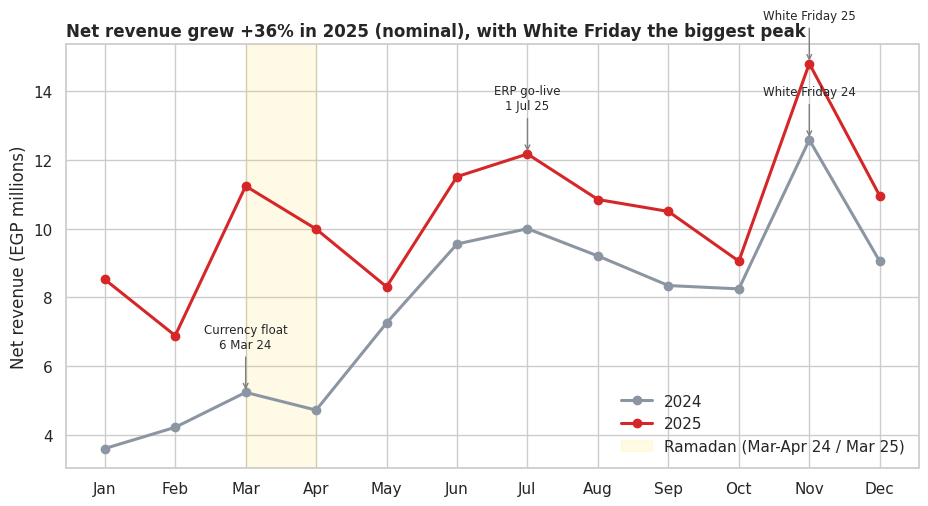

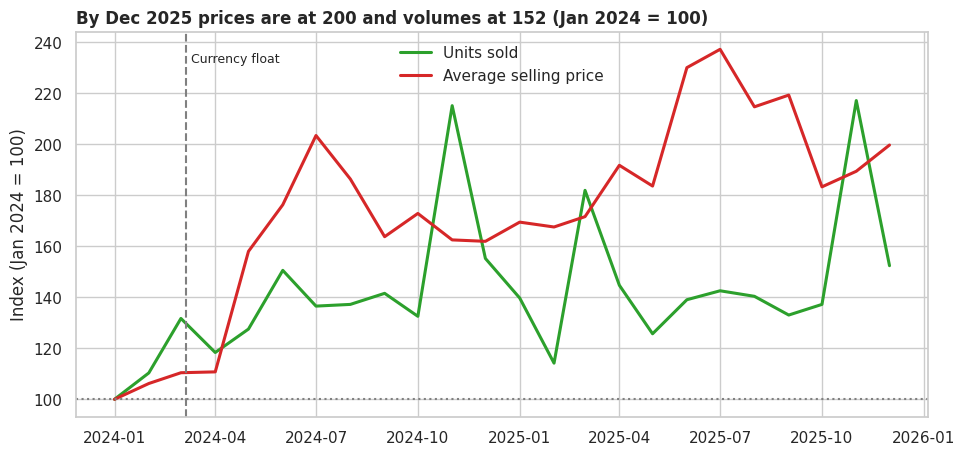

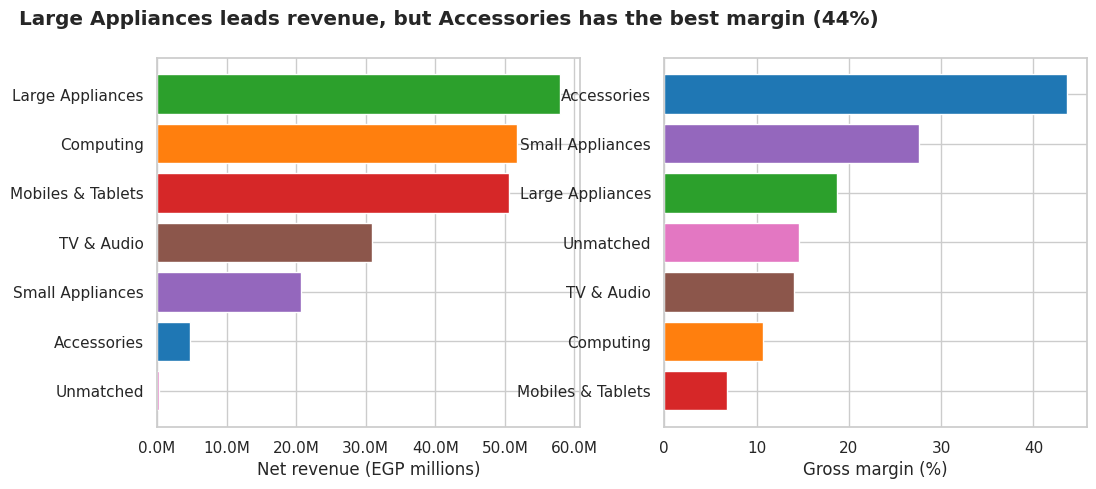

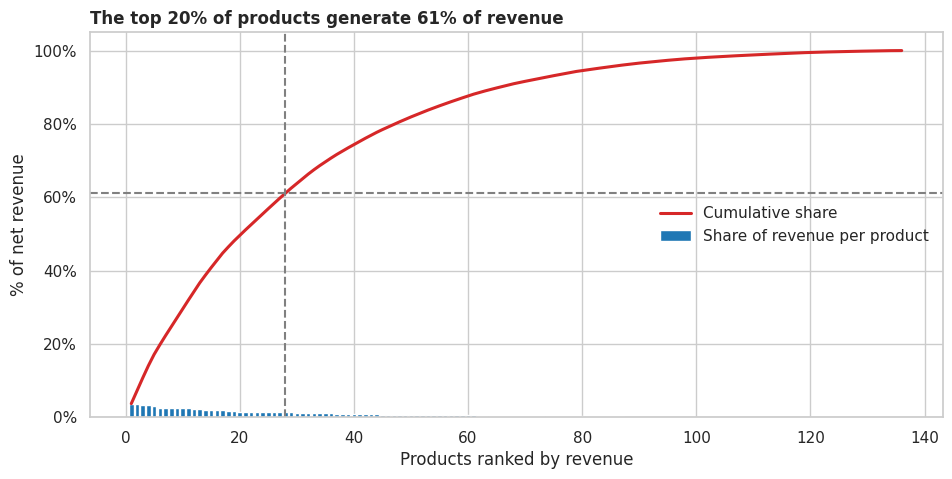

In [61]:
M = FuncFormatter(lambda x, _: f"{x/1e6:.1f}M")
def save(fig, name): fig.savefig(f"charts/{name}.png", dpi=200, bbox_inches="tight")
cats = sorted(df.category.dropna().unique()); CAT_COL = dict(zip(cats, sns.color_palette("tab10", len(cats)).as_hex()))
CH_COL = {"Store": "#1f77b4", "Website": "#ff7f0e", "Mobile App": "#2ca02c"}

# C1
mp = monthly["rev"].groupby([monthly.index.year, monthly.index.month]).sum().unstack(0) / 1e6
fig, ax = plt.subplots(figsize=(11, 5.5))
for y, c in [(2024, "#8c96a3"), (2025, "#d62728")]: ax.plot(mp.index, mp[y], marker="o", lw=2.2, color=c, label=str(y))
ax.axvspan(3, 4, alpha=.10, color="gold", label="Ramadan (Mar-Apr 24 / Mar 25)")
for y, m, t in [(2024, 3, "Currency float\n6 Mar 24"), (2024, 11, "White Friday 24"), (2025, 7, "ERP go-live\n1 Jul 25"), (2025, 11, "White Friday 25")]:
    if m in mp.index and pd.notna(mp.loc[m, y]):
        ax.annotate(t, (m, mp.loc[m, y]), xytext=(0, 32), textcoords="offset points", ha="center", fontsize=8.5, arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Net revenue (EGP millions)"); ax.set_title(f"Net revenue grew {g_rev:+.0%} in 2025 (nominal), with White Friday the biggest peak", loc="left", fontweight="bold"); ax.legend(frameon=False)
save(fig, "C1_monthly_revenue"); plt.show()

# C2
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly.idx_units, lw=2.2, color="#2ca02c", label="Units sold"); ax.plot(monthly.index, monthly.idx_asp, lw=2.2, color="#d62728", label="Average selling price")
ax.axhline(100, ls=":", color="grey"); ax.axvline(pd.Timestamp("2024-03-06"), ls="--", color="grey"); ax.text(pd.Timestamp("2024-03-10"), ax.get_ylim()[1] * .95, "Currency float", fontsize=9)
ax.set_ylabel("Index (Jan 2024 = 100)"); ax.legend(frameon=False)
ax.set_title(f"By {monthly.index[-1]:%b %Y} prices are at {monthly.idx_asp.iloc[-1]:.0f} and volumes at {monthly.idx_units.iloc[-1]:.0f} (Jan 2024 = 100)", loc="left", fontweight="bold")
save(fig, "C2_units_vs_price"); plt.show()

# C3
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
t = cat_tbl.sort_values("rev"); axes[0].barh(t.index, t.rev, color=[CAT_COL[c] for c in t.index]); axes[0].xaxis.set_major_formatter(M); axes[0].set_xlabel("Net revenue (EGP millions)")
t2 = cat_tbl.sort_values("gm"); axes[1].barh(t2.index, t2.gm, color=[CAT_COL[c] for c in t2.index]); axes[1].set_xlabel("Gross margin (%)")
fig.suptitle(f"{cat_tbl.rev.idxmax()} leads revenue, but {cat_tbl.gm.idxmax()} has the best margin ({cat_tbl.gm.max():.0f}%)", x=0.01, ha="left", fontweight="bold")
save(fig, "C3_category"); plt.show()

# C4: Pareto (both series on one % axis)
fig, ax = plt.subplots(figsize=(11, 5)); x = np.arange(1, len(prod_tbl) + 1)
ax.bar(x, prod_tbl.share, color="#1f77b4", label="Share of revenue per product"); ax.plot(x, prod_tbl.cum, color="#d62728", lw=2.2, label="Cumulative share")
ax.axvline(n20, ls="--", color="grey"); ax.axhline(top20, ls="--", color="grey"); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("Products ranked by revenue"); ax.set_ylabel("% of net revenue"); ax.legend(frameon=False, loc="center right")
ax.set_title(f"The top 20% of products generate {top20:.0f}% of revenue", loc="left", fontweight="bold")
save(fig, "C4_pareto"); plt.show()

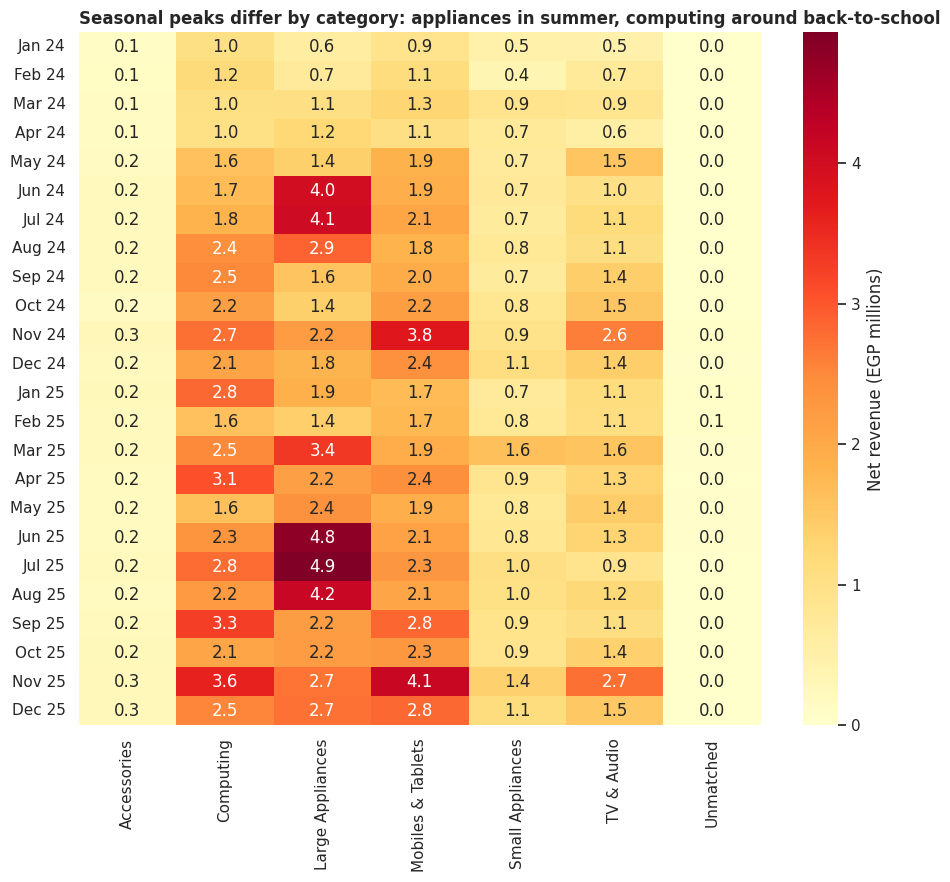

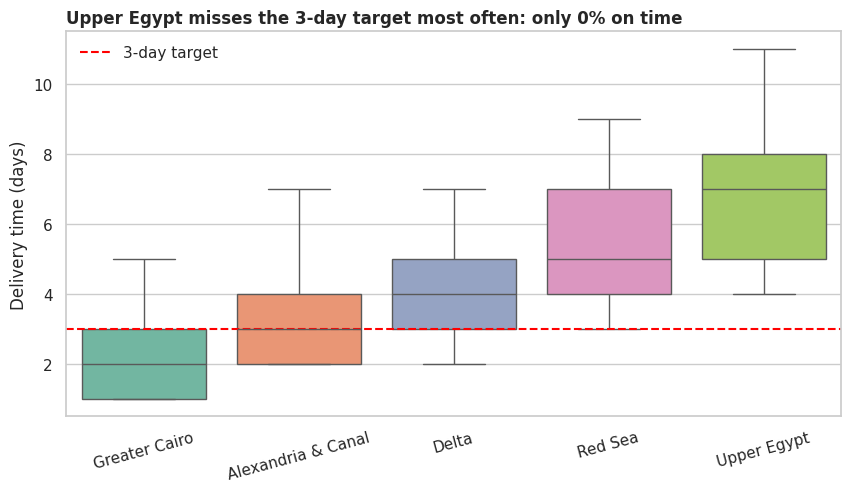

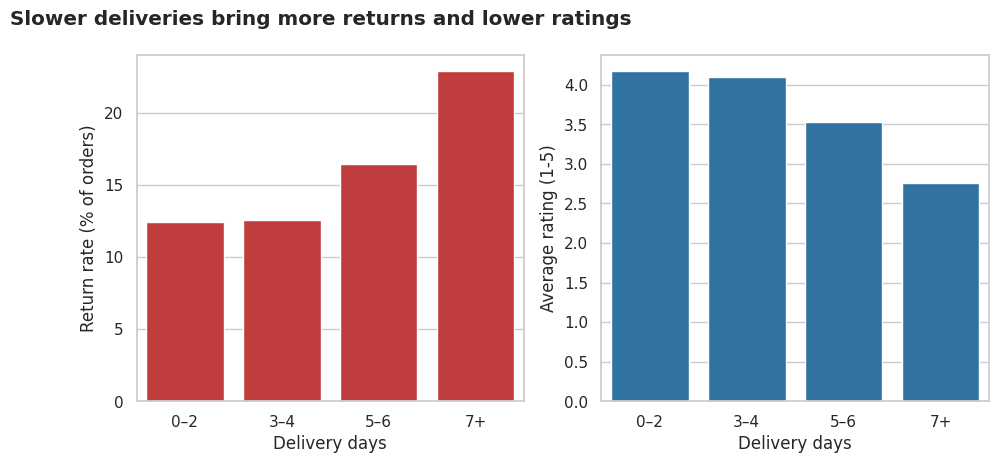

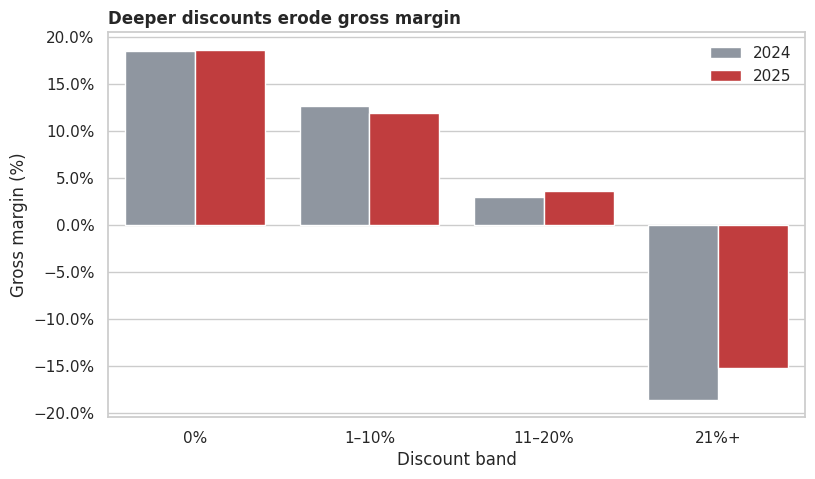

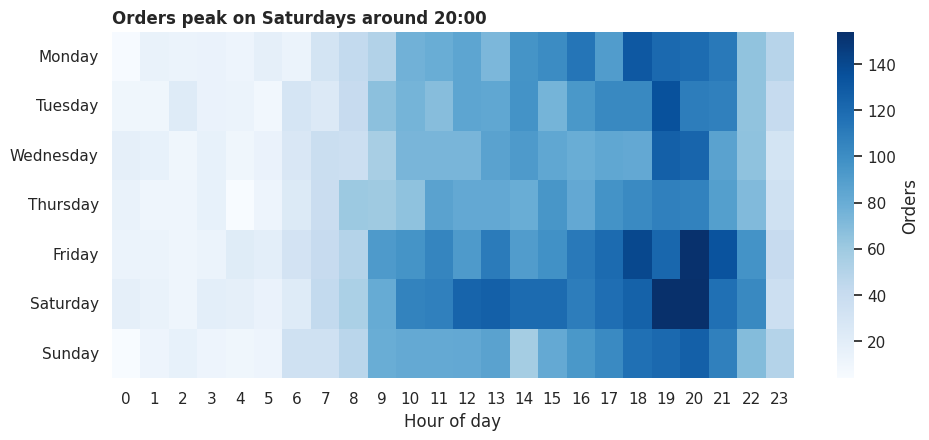

In [62]:
# C5
hm = cat_month.copy().astype(float); hm.index = hm.index.strftime("%b %y")
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(hm / 1e6, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Net revenue (EGP millions)"}, ax=ax)
ax.set_title("Seasonal peaks differ by category: appliances in summer, computing around back-to-school", loc="left", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "C5_heatmap_month_category"); plt.show()

# C6
order_reg = reg_dl.sort_values("mean_days").index
fig, ax = plt.subplots(figsize=(10, 5)); sns.boxplot(data=dl, x="region", y="delivery_days", order=order_reg, palette="Set2", ax=ax)
ax.axhline(ON_TIME_DAYS, color="red", ls="--", label=f"{ON_TIME_DAYS}-day target"); ax.legend(frameon=False); ax.set_ylabel("Delivery time (days)"); ax.set_xlabel("")
w = reg_dl.on_time_pct.idxmin(); ax.set_title(f"{w} misses the 3-day target most often: only {reg_dl.on_time_pct.min():.0f}% on time", loc="left", fontweight="bold")
plt.xticks(rotation=15); save(fig, "C6_delivery_by_region"); plt.show()

# C7
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(data=band, x="band", y="return_rate", color="#d62728", ax=axes[0]); axes[0].set_ylabel("Return rate (% of orders)"); axes[0].set_xlabel("Delivery days")
sns.barplot(data=band, x="band", y="avg_rating", color="#1f77b4", ax=axes[1]); axes[1].set_ylabel("Average rating (1-5)"); axes[1].set_xlabel("Delivery days")
fig.suptitle("Slower deliveries bring more returns and lower ratings", x=0.01, ha="left", fontweight="bold"); save(fig, "C7_returns_rating_by_delivery_band"); plt.show()

# C8
fig, ax = plt.subplots(figsize=(9, 5)); sns.barplot(data=disc, x="disc_band", y="gm", hue="year", palette=["#8c96a3", "#d62728"], ax=ax)
ax.set_ylabel("Gross margin (%)"); ax.set_xlabel("Discount band"); ax.yaxis.set_major_formatter(PercentFormatter()); ax.legend(title="", frameon=False)
ax.set_title("Deeper discounts erode gross margin", loc="left", fontweight="bold"); save(fig, "C8_margin_by_discount"); plt.show()

# C9
hh = timed.assign(hour=timed.order_date.dt.hour).pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count").reindex(wd_order).fillna(0).astype(float)
fig, ax = plt.subplots(figsize=(11, 4.5)); sns.heatmap(hh, cmap="Blues", cbar_kws={"label": "Orders"}, ax=ax); ax.set_xlabel("Hour of day"); ax.set_ylabel("")
ax.set_title(f"Orders peak on {hh.sum(1).idxmax()}s around {int(hh.sum(0).idxmax())}:00", loc="left", fontweight="bold"); save(fig, "C9_weekday_hour"); plt.show()

In [63]:
# C10 (Plotly)
mc = sales.groupby(["ym", "channel"]).net_revenue.sum().reset_index()
f10 = px.area(mc, x="ym", y="net_revenue", color="channel", groupnorm="percent", color_discrete_map=CH_COL,
              title=f"App share of revenue rose from {app_24:.0f}% to {app_25:.0f}%", labels={"ym": "Month", "net_revenue": "Share of net revenue (%)", "channel": "Channel"})
f10.show()

# C11
tm = sales.groupby(["category", "sub_category", "product_name"]).agg(rev=("net_revenue", "sum"), gp=("gross_profit", "sum")).reset_index(); tm["gm_pct"] = tm.gp / tm.rev * 100
f11 = px.treemap(tm, path=["category", "sub_category", "product_name"], values="rev", color="gm_pct", color_continuous_scale="RdYlGn",
                 title="Revenue by category → sub-category → product (colour = gross margin %)", labels={"gm_pct": "Gross margin %"}); f11.show()

# C12: revenue / AOV / on-time by city, switch metric with buttons
cy = sales.groupby(["city", "year"]).agg(rev=("net_revenue", "sum"), orders=("order_id", "nunique")).reset_index(); cy["AOV"] = cy.rev / cy.orders
ot = dl.groupby(["city", "year"]).on_time.mean().mul(100).reset_index().rename(columns={"on_time": "ontime"})
cy = cy.merge(ot, on=["city", "year"], how="left"); order_city = cy.groupby("city").rev.sum().sort_values(ascending=False).index
metrics = [("rev", "Net revenue (EGP)"), ("AOV", "AOV (EGP)"), ("ontime", "On-time delivery (%)")]
f12 = go.Figure()
for mi, (m, lab) in enumerate(metrics):
    for y, c in [(2024, "#8c96a3"), (2025, "#d62728")]:
        s = cy[cy.year == y].set_index("city").reindex(order_city)
        f12.add_trace(go.Bar(x=s.index, y=s[m], name=str(y), marker_color=c, visible=(mi == 0), legendgroup=str(y), showlegend=(mi == 0)))
f12.update_layout(barmode="group", title="City performance (use the buttons to switch metric)", yaxis_title=metrics[0][1],
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.15, buttons=[
                      dict(label=lab, method="update", args=[{"visible": [j // 2 == mi for j in range(6)], "showlegend": [(j // 2 == mi) for j in range(6)]}, {"yaxis": {"title": lab}}])
                      for mi, (m, lab) in enumerate(metrics)])])
f12.show()

# dashboard HTML (all Plotly charts in one file)
parts = [f.to_html(full_html=False, include_plotlyjs=("cdn" if i == 0 else False)) for i, f in enumerate([f10, f11, f12])]
open("orbitra_dashboard.html", "w", encoding="utf-8").write("<html><head><meta charset='utf-8'><title>Orbitra Dashboard</title></head><body style='font-family:sans-serif'><h1>Orbitra 2024-2025 Dashboard</h1>" + "<hr>".join(parts) + "</body></html>")

56487

## Phase 6: PDF skeleton for ExCo (edit the findings text, then re-run)

In [64]:
from matplotlib.backends.backend_pdf import PdfPages
findings = [
    f"1. Net revenue {kp.loc['net_revenue',2025]/1e6:,.1f}M EGP in 2025 ({g_rev:+.0%} vs 2024); gross margin {kp.loc['GM_%',2025]:.1f}% ({kp.loc['GM_%','growth_%']:+.1f} pp).",
    f"2. Units {kp.loc['units','growth_%']:+.0f}% vs ASP {kp.loc['ASP','growth_%']:+.0f}%: price effect = {pvm['Price (same products)']/pvm.sum():.0%} of the revenue change.",
    f"3. Mobile App share of revenue: {app_24:.0f}% → {app_25:.0f}%.",
    f"4. Worst on-time delivery: {w} ({reg_dl.on_time_pct.min():.0f}% within {ON_TIME_DAYS} days).",
    f"5. Top 20% of products = {top20:.0f}% of revenue.",
    f"6. White Friday GP uplift vs previous 4 weeks: " + ", ".join(f"{y}: {v:+.0f}%" for y, v in wf['GP_uplift_%'].items()) + " per day.",
]
with PdfPages("orbitra_review_2024_2025.pdf") as pdf:
    fig = plt.figure(figsize=(8.27, 11.69)); fig.text(.08, .93, "Orbitra: 2024-2025 Commercial Performance Review", fontsize=16, fontweight="bold")
    fig.text(.08, .88, "Executive summary", fontsize=12, fontweight="bold")
    for i, t in enumerate(findings): fig.text(.08, .83 - i * .06, t, fontsize=9.5, wrap=True)
    pdf.savefig(fig); plt.close(fig)
    pngs = sorted(f for f in os.listdir("charts") if f.endswith(".png"))
    for i in range(0, len(pngs), 2):
        fig, axs = plt.subplots(2, 1, figsize=(8.27, 11.69))
        for ax, f in zip(axs, pngs[i:i + 2]): ax.imshow(plt.imread(f"charts/{f}")); ax.axis("off")
        for ax in axs[len(pngs[i:i + 2]):]: ax.axis("off")
        pdf.savefig(fig); plt.close(fig)
print("saved: clean csv, DQ log, dashboard html, charts/, review pdf")

saved: clean csv, DQ log, dashboard html, charts/, review pdf


In [65]:
f12.update_xaxes(type="category", categoryorder="array", categoryarray=list(order_city))
f12.show()
parts = [f.to_html(full_html=False, include_plotlyjs=("cdn" if i == 0 else False)) for i, f in enumerate([f10, f11, f12])]
open("orbitra_dashboard.html", "w", encoding="utf-8").write(
    "<html><head><meta charset='utf-8'><title>Orbitra Dashboard</title></head><body style='font-family:sans-serif'>"
    "<h1>Orbitra 2024-2025 Dashboard</h1>" + "<hr>".join(parts) + "</body></html>")

56712

In [66]:
import zipfile, glob
from google.colab import files
out = ["orbitra_orders_clean.csv", "data_quality_log.xlsx",
       "orbitra_review_2024_2025.pdf", "orbitra_dashboard.html"] + glob.glob("charts/*.png")
with zipfile.ZipFile("orbitra_results.zip", "w") as z:
    for f in out: z.write(f)
files.download("orbitra_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>